# TP : Principal Component Analysis
Student: Guilherme LORETE SCHMIDT

In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.covariance import MinCovDet

## Question 1
We start by defining the distribution parameters.

In [2]:
# Distribution parameters
mu1 = [0, 0]
mu2 = mu3 = [2, 2]
sigma1 = sigma2 = [[1, 1], [1, 4]]
sigma3 = [[4, 4], [4, 16]]

npoints = 100

The we create a function that generates a given number of samples of a student distribution with the desired mean, scatter and degrees of freedom. The function generates the student distribution samples based on samples from a normal distribution $Z$ and a chi-squared distribution $W$:
$$
X = \mathbf{\mu} + \sqrt{\dfrac{\nu}{W_nu}} Z
$$

In [3]:
def rmvt(mu, sigma, nu, npoints):
    mu = np.asarray(mu)
    sigma = np.asarray(sigma)

    # multivariate normal distribution
    Gauss = stats.multivariate_normal.rvs(mean=np.zeros_like(mu), cov=sigma, size=npoints)

    #  chi-squared distribution
    Chi = stats.chi2.rvs(df=nu, size=npoints).reshape(npoints, 1)

    return mu + Gauss * np.sqrt(nu / Chi)

Using the function above, we generate samples for the three desired distributions and plot them.

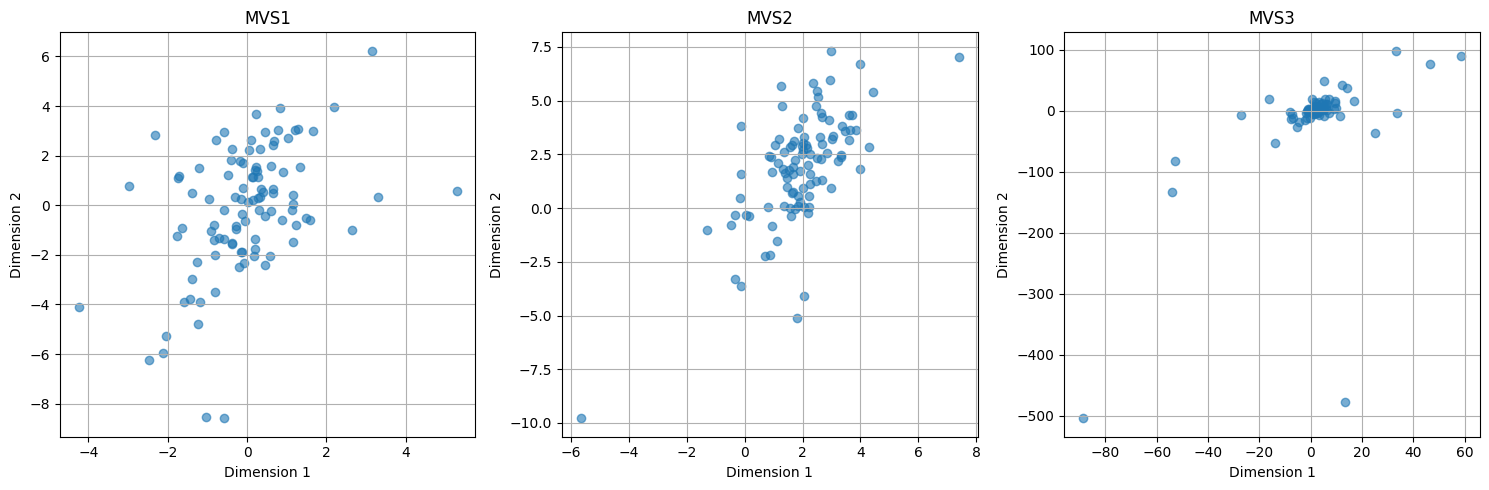

In [4]:
MVS1 = rmvt(mu1, sigma1, 5, npoints)
MVS2 = rmvt(mu2, sigma2, 3, npoints)
MVS3 = rmvt(mu3, sigma3, 1, npoints)

# Plotting the distributions
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.scatter(MVS1[:, 0], MVS1[:, 1], alpha=0.6)
plt.title('MVS1')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.grid()

plt.subplot(1, 3, 2)
plt.scatter(MVS2[:, 0], MVS2[:, 1], alpha=0.6)
plt.title('MVS2')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.grid()

plt.subplot(1, 3, 3)
plt.scatter(MVS3[:, 0], MVS3[:, 1], alpha=0.6)
plt.title('MVS3')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.grid()

plt.tight_layout()
plt.show()

From the plots, we see that the first distribution is centered at 0, as expected, and the second at 2, agreeing with the given $\mu$ inputs. In addition, both share the same scatter matrix and have a roughly similar distribution arround the center point (the variance itself is also influenced by the number of degrees of freedom of each one).

Concerning the cauchy distribution, we see that the distribution is heavy-tailled, generating points extremelly far from the main cluster.

## Question 2

Now we generate 1000 points of the desired three-dimensional Student-t5 distribution and project it into a five-dimensional space, followed by a shift and an addition of random normal noise.

In [5]:
# defines parameters and matrixes
npoints = 1000
mu = np.zeros(3)
sigma = [[1, 1, 1], [1, 4, 4], [1, 4, 9]]
proj_matrix = np.array([[1, 1, 1, 1, 1], [1, -1, 1, -1, 0], [0, -1, -1, 0, 2]])
proj_matrix = proj_matrix / np.linalg.norm(proj_matrix, axis=0)
shift = np.array([1, 2, 3, 4, 5])

# generates Student-t5 samples
stdist = rmvt(mu, sigma, 5, npoints)

# generates noise
noise = stats.multivariate_normal.rvs(mean=np.zeros(5), cov=np.diag(0.025 * np.ones(5)), size=npoints)

# defines data as a series of transformations on the Student-t5 samples
data = stdist @ proj_matrix + shift + noise

## Question 3

We start by applying the PCA function from `sklearn` on the data, printing the explained variance, singular values and PCA components.

In [6]:
# Applies PCA
pca = PCA(n_components=5).fit(data)
Y = pca.transform(data)

print('Explained variances:\n', pca.explained_variance_)
print('\nSingular values:\n',pca.singular_values_)
print('\nPCA components:\n', pca.components_)

Explained variances:
 [2.74349793e+01 5.27495592e+00 2.02284609e+00 2.55478342e-02
 2.37463720e-02]

Singular values:
 [165.55224044  72.59256823  44.95356763   5.05195867   4.87058781]

PCA components:
 [[ 0.32554082 -0.58585979 -0.15803235 -0.2030093   0.69613538]
 [ 0.63410677  0.01681639  0.71775126 -0.22063963 -0.18378547]
 [ 0.26166378  0.45447367  0.09545374  0.69389007  0.48413934]
 [ 0.26993985  0.64329746 -0.39127471 -0.57915303  0.157438  ]
 [ 0.59211175 -0.19001992 -0.54557455  0.30529284 -0.4716363 ]]


From the explained variances, one can see that the first three values are a lot more significant than the last two. This is expected, since the original data has rank 3 and these first 3 variances capture much of the original data structure. This is further supported by the fact that the last two values are close to 0.025, the variance of the applied noise.

We then use the fitted data to plot graphs for pairs of the first three principal components

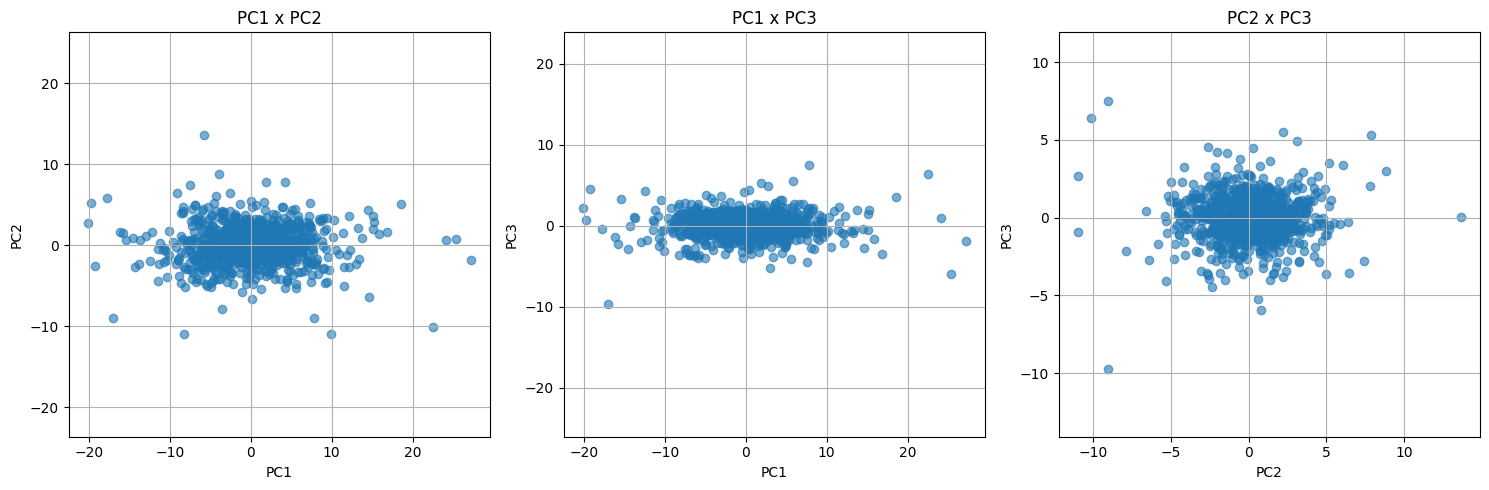

In [7]:
# Plotting the distributions
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.scatter(Y[:,0], Y[:,1], alpha=0.6)
plt.title('PC1 x PC2')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.grid()
plt.axis('equal')

plt.subplot(1, 3, 2)
plt.scatter(Y[:,0], Y[:,2], alpha=0.6)
plt.title('PC1 x PC3')
plt.xlabel('PC1')
plt.ylabel('PC3')
plt.grid()
plt.axis('equal')

plt.subplot(1, 3, 3)
plt.scatter(Y[:,1], Y[:,2], alpha=0.6)
plt.title('PC2 x PC3')
plt.xlabel('PC2')
plt.ylabel('PC3')
plt.grid()
plt.axis('equal')

plt.tight_layout()
plt.show()

Based on the direction of elongation in each graph, we see a clear hierarchy in the variance of each principal component: the highest is PC1, the middle one is PC2 and the smallest is PC3. This agrees with the expected behaviour of the PCA, since the algorithm chooses as principals components the vectors that maximizes the variance.

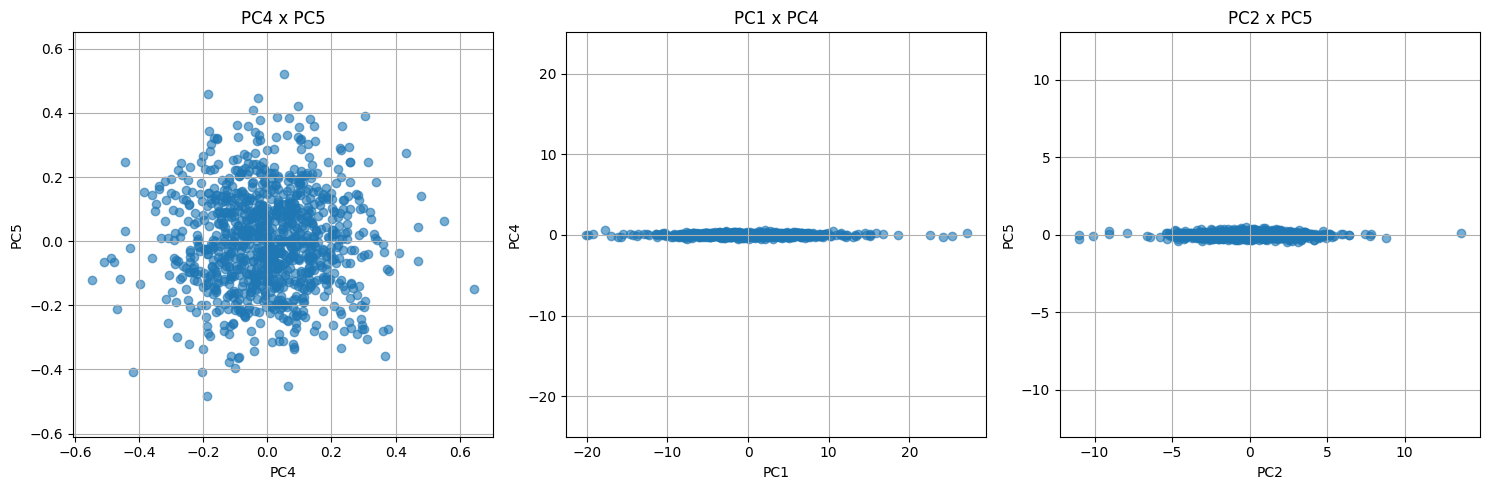

In [8]:
# Plotting the distributions
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.scatter(Y[:,3], Y[:,4], alpha=0.6)
plt.title('PC4 x PC5')
plt.xlabel('PC4')
plt.ylabel('PC5')
plt.grid()
plt.axis('equal')

plt.subplot(1, 3, 2)
plt.scatter(Y[:,0], Y[:,3], alpha=0.6)
plt.title('PC1 x PC4')
plt.xlabel('PC1')
plt.ylabel('PC4')
plt.grid()
plt.axis('equal')

plt.subplot(1, 3, 3)
plt.scatter(Y[:,1], Y[:,4], alpha=0.6)
plt.title('PC2 x PC5')
plt.xlabel('PC2')
plt.ylabel('PC5')
plt.grid()
plt.axis('equal')

plt.tight_layout()
plt.show()

From the PC4 x PC5 plot, we see that both have the same variance and form a circular pattern with more points arround the center, which agrees with the idea that these two dimensions represent the noise, normally distributed and with equal variance in all dimensions. The other two graphs show that the variance of the two last principal components are practically irrelevant in relation to the first two.

Thus we can affirm that the first three principal components contain the data, while the last two contain noise.

## Question 4

Let $Y$ be the centered version of the data. We calculate the SVD of $Y^T Y$ and print the respective V matrix, which should correspond to the previously calculated principal components.

In [9]:
# Computes SVD
centered = data - np.mean(data, axis=0)
A = centered.T @ centered
[u, s, v] = np.linalg.svd(A)

# Prints V matrix
print(v)

[[-0.32554082  0.58585979  0.15803235  0.2030093  -0.69613538]
 [-0.63410677 -0.01681639 -0.71775126  0.22063963  0.18378547]
 [ 0.26166378  0.45447367  0.09545374  0.69389007  0.48413934]
 [ 0.26993985  0.64329746 -0.39127471 -0.57915303  0.157438  ]
 [-0.59211175  0.19001992  0.54557455 -0.30529284  0.4716363 ]]


We see that the vectors are similar to the calculated principal components, some with the sign inverted. To check, we invert the sign of the necessary vectors and compare the matrices.

In [10]:
# function to align vectors (useful to align v and pca)
def align_vectors_by_sign(reference_vectors, vectors_to_align):
    aligned_vectors = np.copy(vectors_to_align)
    for i in range(reference_vectors.shape[0]):
        if np.dot(reference_vectors[i], aligned_vectors[i]) < 0:
            aligned_vectors[i] = -aligned_vectors[i]
    return aligned_vectors

# aligns v and pca in terms of their sign
aligned_v = align_vectors_by_sign(pca.components_, v)

print("Aligned V matrix:")
print(aligned_v)

print("\nPCA Components matrix:")
print(pca.components_)

# Now we can properly compare both matrixes
print("\nAre aligned_v and pca.components_ approximately equal?")
print(np.allclose(pca.components_, aligned_v))


Aligned V matrix:
[[ 0.32554082 -0.58585979 -0.15803235 -0.2030093   0.69613538]
 [ 0.63410677  0.01681639  0.71775126 -0.22063963 -0.18378547]
 [ 0.26166378  0.45447367  0.09545374  0.69389007  0.48413934]
 [ 0.26993985  0.64329746 -0.39127471 -0.57915303  0.157438  ]
 [ 0.59211175 -0.19001992 -0.54557455  0.30529284 -0.4716363 ]]

PCA Components matrix:
[[ 0.32554082 -0.58585979 -0.15803235 -0.2030093   0.69613538]
 [ 0.63410677  0.01681639  0.71775126 -0.22063963 -0.18378547]
 [ 0.26166378  0.45447367  0.09545374  0.69389007  0.48413934]
 [ 0.26993985  0.64329746 -0.39127471 -0.57915303  0.157438  ]
 [ 0.59211175 -0.19001992 -0.54557455  0.30529284 -0.4716363 ]]

Are aligned_v and pca.components_ approximately equal?
True


The analysis of the relationship between Principal Component Analysis and the Singular Value Decomposition reveals that the principal components derived from the eigenvalue decomposition of the data covariance matrix in the case of `sklearn.decomposition.PCA` implementation are equivalent to the singular vectors obtained through decomposition using `np.linalg.svd`.

The alignment between these two methods confirms that the directions of maximum variance identified by the PCA implementation are identical to the singular vectors.

## Question 5

We generate 100 samples of noise from a cauchy distribution and use them as substitute for the last 100 samples of the data.

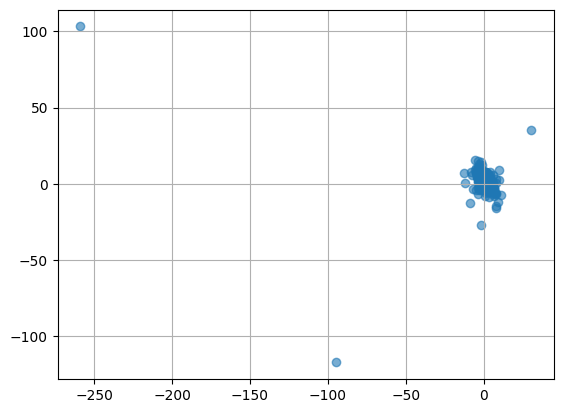

In [11]:
# generates 100 samples of the standard cauchy distribution
noise = rmvt(np.zeros(5), np.diag(np.ones(5)), 1, 100)

# replaces 100 last data samples with noise
contaminated_data = np.append(data[0:900,:], noise, axis=0)

plt.scatter(contaminated_data[:,0], contaminated_data[:,1], alpha=0.6)
plt.grid()

From the plot, we see that the addition of the Cauchy distribution samples introduces extreme outliers in the data.

Since PCA relies on maximizing the variance to choose the principal components, a few Cauchy outliers can significantly skew the principal components and pull them away from the underlying data they should represent.

## Question 6

We start by applying PCA on the contaminated data and extracting the explained variances, sigular values and principal components.

In [12]:
# Applies PCA
contaminated_pca = PCA(n_components=5).fit(contaminated_data)
contaminated_Y = contaminated_pca.transform(contaminated_data)

print('Explained variances:\n', contaminated_pca.explained_variance_)
print('\nSingular values:\n', contaminated_pca.singular_values_)
print('\nContaminated PCA components:\n', contaminated_pca.components_)

print('\nOriginal PCA components:\n', pca.components_)

Explained variances:
 [213.95687262  55.39016301  24.89467632  12.79065538   3.45771323]

Singular values:
 [462.32338871 235.23344331 157.70155878 113.03921762  58.7729148 ]

Contaminated PCA components:
 [[-0.55767494  0.19809021 -0.21715833  0.20612018  0.74840876]
 [-0.48289235 -0.43315533 -0.13360773  0.59970072 -0.44910963]
 [-0.29252835  0.83290072  0.20750695  0.10696553 -0.40767976]
 [ 0.13744705 -0.09284778  0.85163564  0.42570845  0.25685921]
 [ 0.59274709  0.26606842 -0.40822646  0.63655652  0.07749472]]

Original PCA components:
 [[ 0.32554082 -0.58585979 -0.15803235 -0.2030093   0.69613538]
 [ 0.63410677  0.01681639  0.71775126 -0.22063963 -0.18378547]
 [ 0.26166378  0.45447367  0.09545374  0.69389007  0.48413934]
 [ 0.26993985  0.64329746 -0.39127471 -0.57915303  0.157438  ]
 [ 0.59211175 -0.19001992 -0.54557455  0.30529284 -0.4716363 ]]


Analysing the explained variances, we see that now there isn't as great of gap between the first three variances and the last two as there was before, showing that sepparating the data from the noise is more difficult now.

Now taking the contaminated principal components and comparing them to the original ones, it is clear that the noise has led to a completely different choice of vectors, with no resemblance to the original set. This underlines the sensitivity of PCA to outliers in the data.

Now, as a different approach we calculate the Minimum Covariance Determinant estimate of the contaminated dataset, a method highly resistant to outliers.

In [13]:
# Fit MCD to the data
mcd = MinCovDet(random_state=0).fit(contaminated_data)

# Print the estimated mean
print("MCD estimated mean:\n", mcd.location_)

MCD estimated mean:
 [1.01673998 1.97851628 2.9841509  4.00967157 5.04798989]


Notice that the estimated mean is close to the original shift applied to the data, given by $\mu = [1 \ 2 \ 3 \ 4 \ 5]$, showing that it wasn't significantly impacted by the outliers.

Therefore, with the aim of getting a set of principal components that isn't as affected by outliers, we apply SVD to the corrected MCD-estimate of the covariance matrix to calculate the principal components of the dataset.

In [14]:
# gets the corrected covariance
corrected_covariance = mcd.correct_covariance(contaminated_data)

# calculates the svd
A_contaminated = corrected_covariance.T @ corrected_covariance
[u_contaminated, s_contaminated, v_contaminated] = np.linalg.svd(A_contaminated)
print('Components estimated from covariance matrix:\n', v_contaminated)

print('\nOriginal PCA components:\n', pca.components_)

aligned_v_contaminated = align_vectors_by_sign(pca.components_, v_contaminated)

print("\nAligned V matrix:\n", aligned_v_contaminated)

diff = aligned_v_contaminated - aligned_v

print("\nDifference matrix:\n", diff)

Components estimated from covariance matrix:
 [[-0.35424407  0.60388435  0.11185943  0.24841214 -0.66001039]
 [-0.61960793 -0.06982102 -0.73069779  0.17942236  0.21236616]
 [ 0.25950825  0.4260752   0.06002956  0.69031769  0.52055098]
 [ 0.6499013   0.12254367 -0.6639892   0.00088354 -0.3488967 ]
 [-0.02968028  0.65870455 -0.09530472 -0.65540806  0.3557874 ]]

Original PCA components:
 [[ 0.32554082 -0.58585979 -0.15803235 -0.2030093   0.69613538]
 [ 0.63410677  0.01681639  0.71775126 -0.22063963 -0.18378547]
 [ 0.26166378  0.45447367  0.09545374  0.69389007  0.48413934]
 [ 0.26993985  0.64329746 -0.39127471 -0.57915303  0.157438  ]
 [ 0.59211175 -0.19001992 -0.54557455  0.30529284 -0.4716363 ]]

Aligned V matrix:
 [[ 0.35424407 -0.60388435 -0.11185943 -0.24841214  0.66001039]
 [ 0.61960793  0.06982102  0.73069779 -0.17942236 -0.21236616]
 [ 0.25950825  0.4260752   0.06002956  0.69031769  0.52055098]
 [ 0.6499013   0.12254367 -0.6639892   0.00088354 -0.3488967 ]
 [ 0.02968028 -0.658704

From the difference matrix between the original principal components and the new values obtained through the MCD estimates on the contaminated data, we see that the differences on the first three components, which represent the data, are very small, while the differences on the last two, representing the noise, are very significant. Thus we can affirm that the calculation of the principal components through the MCD estimate is resistant to outliers and provides reasonable results, since the principal components corresponding to the data are largely unchanged.